<a href="https://colab.research.google.com/github/Anastetikc/Math_Stat/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%227_anova_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sterolose/sirius-statistics-2026/blob/main/notebooks/7_anova.ipynb)

## Семинар 7. Дисперсионный анализ

In [ ]:
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import scikit_posthocs as sp
import pyartool as art

In [ ]:
pip install scikit-posthocs

In [ ]:
pip install pyartool

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 3.0 MB/s eta 0:00:00


Вернемся к датасету "Palmer Penguins". Подготовим его как раньше.

In [ ]:
df = sns.load_dataset("penguins")
df.insert(2, "body_mass_kg", df.pop("body_mass_g") / 1000)
df = df.dropna()
df.head(2)

,species,island,body_mass_kg,bill_length_mm,bill_depth_mm,flipper_length_mm,sex
0,Adelie,Torgersen,3.75,39.1,18.7,181.0,Male
1,Adelie,Torgersen,3.80,39.5,17.4,186.0,Female


Во всех заданиях используем уровень значимости $\alpha = 0.05$, в парных сравнениях — двусторонние альтернативы.

### Задание 1

Применим однофакторный дисперсионный анализ для сравнения средней массы между полами.

In [ ]:
male = df.loc[df["sex"] == "Male", "body_mass_kg"]
female = df.loc[df["sex"] == "Female", "body_mass_kg"]

result = stats.f_oneway(male, female)
f"statistic = {result.statistic:.2f}, p-value = {result.pvalue:.3g}"

'statistic = 72.96, p-value = 4.9e-16'

Сравните результат с t-тестом Стьюдента.

In [ ]:
ttest_result = stats.ttest_ind(male, female)

print("Результаты t-теста")
print(f"t-statistic = {ttest_result.statistic:.2f}")
print(f"p-value     = {ttest_result.pvalue:.3g}")

print(f"Квадрат t-статистики: {ttest_result.statistic**2:.2f}")
print(f"F-статистика из ANOVA:     {result.statistic:.2f}")

Результаты t-теста
t-statistic = 8.54
p-value     = 4.9e-16
Квадрат t-статистики: 72.96
F-статистика из ANOVA:     72.96


### Задание 2

Теперь оценим различия средней массы тела между видами. Однако напомню, что классическая ANOVA предполагает равенство дисперсий между группами. Проверим это предположение с помощью тестов Бартлетта и Левене.

In [ ]:
groups = df.groupby("species")["body_mass_kg"].apply(list)

pd.DataFrame({
    "test": ["Bartlett", "Levene"],
    "p-value": [
        stats.bartlett(*groups).pvalue,
        stats.levene(*groups).pvalue,
    ],
})

,test,p-value
0,Bartlett,0.058075
1,Levene,0.006367


Примените однофакторный ANOVA к тем же группам, указав необходимое значение параметра `equal_var`.

In [ ]:
result_welch = stats.f_oneway(*groups, equal_var=False)

f"statistic = {result_welch.statistic:.2f}, p-value = {result_welch.pvalue:.3g}"

'statistic = 316.50, p-value = 7.44e-61'

Также ANOVA не отвечает на вопрос, средние каких именно групп различаются. Для каждой пары групп выполните тест Уэлча (можете использовать `combinations` для перебора всех пар). Примените поправку Бонферрони и выведите результат как `pd.DataFrame`.

In [ ]:
pairs = list(combinations(df["species"].unique(), 2))

raw_pvals = [
    stats.ttest_ind(
        df.loc[df["species"] == p[0], "body_mass_kg"],
        df.loc[df["species"] == p[1], "body_mass_kg"],
        equal_var=False,
    ).pvalue
    for p in pairs
]

df_posthoc = pd.DataFrame(
    {
        "comparison": [f"{p[0]} vs {p[1]}" for p in pairs],
        "p-value_raw": raw_pvals,
        "p-value_bonferroni": [min(p * len(pairs), 1.0) for p in raw_pvals],
    }
)

df_posthoc

,comparison,p-value_raw,p-value_bonferroni
0,Adelie vs Chinstrap,6.548333e-01,1.000000e+00
1,Adelie vs Gentoo,1.223170e-63,3.669511e-63
2,Chinstrap vs Gentoo,1.885263e-48,5.655789e-48


При равных дисперсиях для всех парных сравнений удобно применять тест Тьюки. Для аналога с неравными дисперсиями — теста Геймса — Хауэлла — укажем `use_var="unequal"`.

In [ ]:
pairwise_tukeyhsd(df["body_mass_kg"], df["species"], use_var="unequal").summary()

group1,group2,meandiff,p-adj,lower,upper,reject
Adelie,Chinstrap,0.0269,0.8954,-0.1153,0.1692,False
Adelie,Gentoo,1.3863,0.0,1.2457,1.5269,True
Chinstrap,Gentoo,1.3593,0.0,1.2046,1.5141,True


Результат может быть визуализирован.

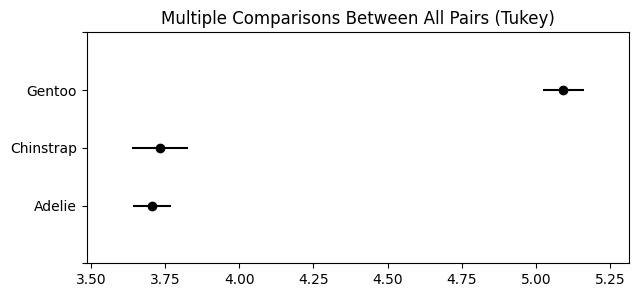

In [ ]:
tukey = pairwise_tukeyhsd(df["body_mass_kg"], df["species"])
tukey.plot_simultaneous(figsize=(7, 3))
plt.show()

### Задание 3

Давайте применим двухфакторный ANOVA для вида и пола птицы. Используем `ols` и `anova_lm` из `statsmodels` с R-подобным синтаксисом. Будем считать дисперсии в группах «вид × пол» одинаковыми; проверку пропустим.

In [ ]:
model = ols("body_mass_kg ~ species + sex", df).fit()
anova_lm(model)

,df,sum_sq,mean_sq,F,PR(>F)
species,2.0,145.190219,72.595110,724.208043,3.079053e-121
sex,1.0,37.090262,37.090262,370.012058,8.729411e-56
Residual,329.0,32.979185,0.100241,NaN,NaN


До этого мы не рассматривали взаимодействие факторов. То есть предполагали, что разница средней массы между полами одинакова у разных видов. Чтобы учесть различия полового диморфизма между видами, можно использовать запись `species + sex + species:sex` либо сокращенный вариант `species * sex`.

In [ ]:
model = ols("body_mass_kg ~ species * sex", df).fit()
anova_lm(model)

,df,sum_sq,mean_sq,F,PR(>F)
species,2.0,145.190219,72.595110,758.358072,1.540207e-123
sex,1.0,37.090262,37.090262,387.459976,1.902273e-57
species:sex,2.0,1.676557,0.838278,8.756997,1.973489e-04
Residual,327.0,31.302628,0.095727,NaN,NaN


Напомню, что ANOVA предполагает нормальность ошибок модели, а не исходной переменной в целом. Проверим это предположение по остаткам: постройте гистограмму, Q–Q plot и выполните тест Шапиро — Уилка. Получить остатки модели можно как `model.resid`.

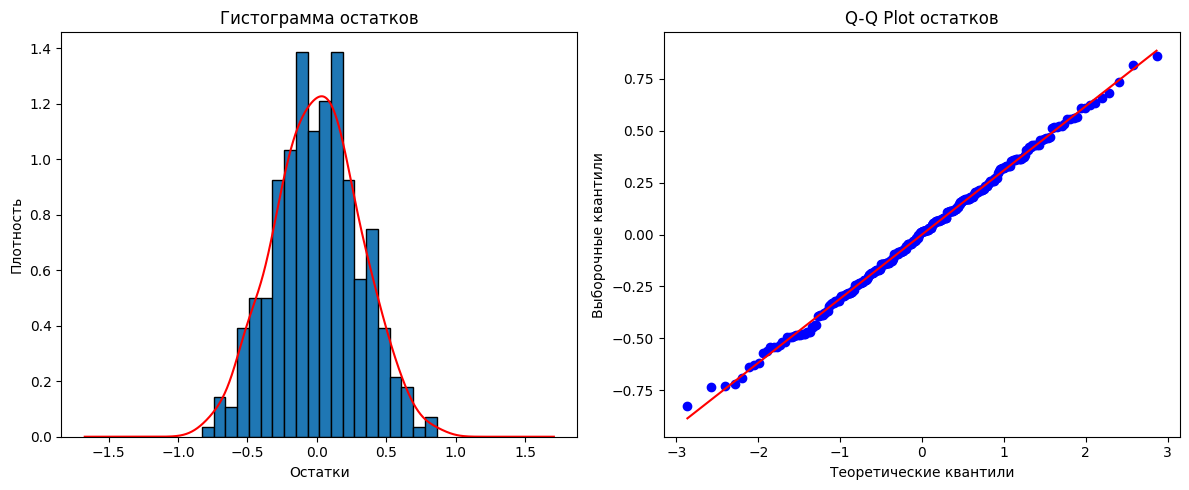

Тест Шапиро-Уилка: statistic = 0.998, p-value = 0.937


In [ ]:
residuals = model.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(residuals, bins=20, edgecolor="black", density=True)

residuals.plot(kind="kde", ax=axes[0], color="red")
axes[0].set_title("Гистограмма остатков")
axes[0].set_xlabel("Остатки")
axes[0].set_ylabel("Плотность")

stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot остатков")
axes[1].set_xlabel("Теоретические квантили")
axes[1].set_ylabel("Выборочные квантили")

plt.tight_layout()
plt.show()

shapiro_test = stats.shapiro(residuals)
print(f"Тест Шапиро-Уилка: statistic = {shapiro_test.statistic:.3f}, p-value = {shapiro_test.pvalue:.3g}")

Выполните тест Тьюки и визуализируйте результат. Тест не умеет работать с несколькими категориальными переменными, объединим их в одну.

          Multiple Comparison of Means - Tukey HSD, FWER=0.05           
     group1           group2      meandiff p-adj   lower   upper  reject
------------------------------------------------------------------------
   Adelie_Female      Adelie_Male   0.6747    0.0  0.5278  0.8215   True
   Adelie_Female Chinstrap_Female   0.1584 0.1376 -0.0258  0.3425  False
   Adelie_Female   Chinstrap_Male   0.5701    0.0   0.386  0.7543   True
   Adelie_Female    Gentoo_Female   1.3109    0.0  1.1549  1.4669   True
   Adelie_Female      Gentoo_Male    2.116    0.0  1.9621  2.2699   True
     Adelie_Male Chinstrap_Female  -0.5163    0.0 -0.7004 -0.3321   True
     Adelie_Male   Chinstrap_Male  -0.1045 0.5812 -0.2887  0.0796  False
     Adelie_Male    Gentoo_Female   0.6362    0.0  0.4802  0.7923   True
     Adelie_Male      Gentoo_Male   1.4413    0.0  1.2875  1.5952   True
Chinstrap_Female   Chinstrap_Male   0.4118    0.0  0.1966  0.6269   True
Chinstrap_Female    Gentoo_Female   1.1525    0.0  

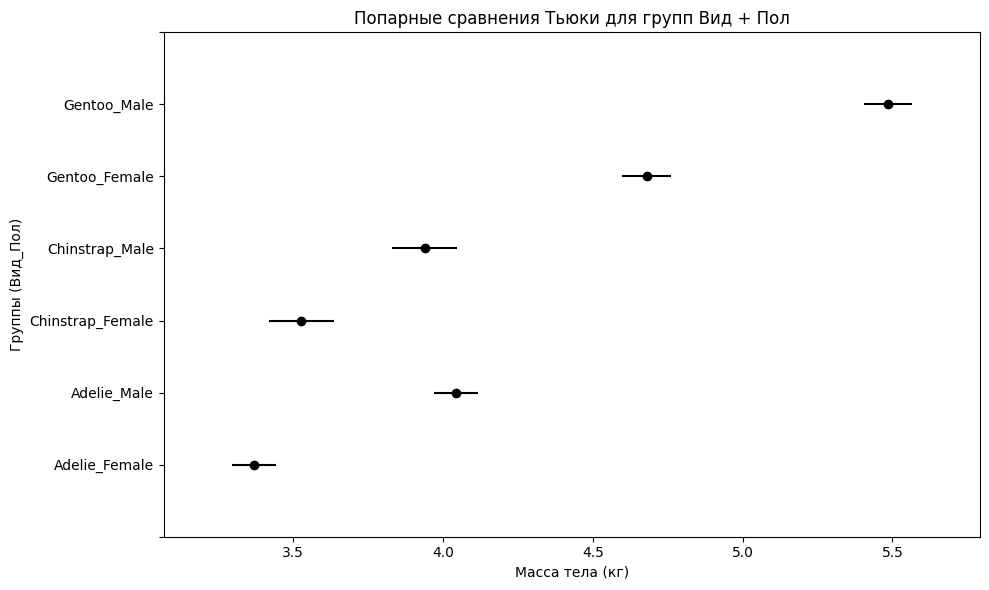

In [ ]:
df["species_sex"] = df["species"].astype(str) + "_" + df["sex"].astype(str)

tukey_two_way = pairwise_tukeyhsd(
    endog=df["body_mass_kg"], groups=df["species_sex"], alpha=0.05
)

print(tukey_two_way)

fig, ax = plt.subplots(figsize=(10, 6))
tukey_two_way.plot_simultaneous(ax=ax)

ax.set_title("Попарные сравнения Тьюки для групп Вид + Пол")
ax.set_xlabel("Масса тела (кг)")
ax.set_ylabel("Группы (Вид_Пол)")

plt.tight_layout()
plt.show()

Различия можно визуализировать и с более красочным и понятным графиком.

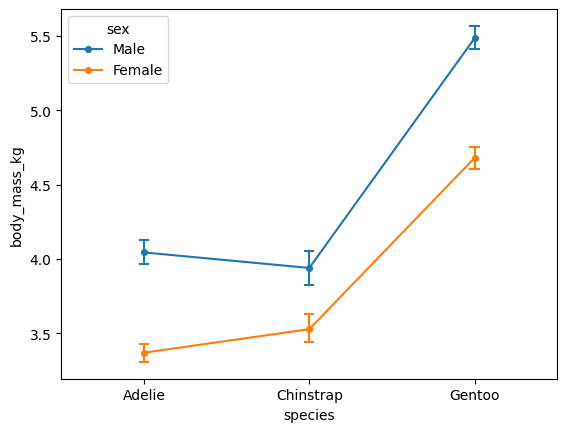

In [ ]:
sns.pointplot(
    df, x="species", y="body_mass_kg", hue="sex",
    errorbar=("ci", 95), capsize=0.05,
    linewidth=1.5, markersize=4,
)
plt.show()

Однако такой график не имеет поправки на множественные сравнения и не заменяет тесты.

### Задание 4

Теперь давайте оценим различие средней длины клюва в группах «вид × пол». Выполните тест Левена для оценки равенства дисперсий в группах. Постройте двухфакторную ANOVA. Проверьте нормальность остатков.

In [ ]:
model = ols("bill_length_mm ~ species * sex", df).fit()
anova_lm(model)


,df,sum_sq,mean_sq,F,PR(>F)
species,2.0,7015.385745,3507.692873,654.189409,5.034477e-115
sex,1.0,1135.683888,1135.683888,211.806563,2.422971e-37
species:sex,2.0,24.494427,12.247213,2.284122,1.034865e-01
Residual,327.0,1753.338642,5.361892,NaN,NaN


statistic = 1.40, p-value = 0.222
Вывод: дисперсии равны
Тест Шапиро-Уилка: statistic = 0.971, p-value = 3.45e-06


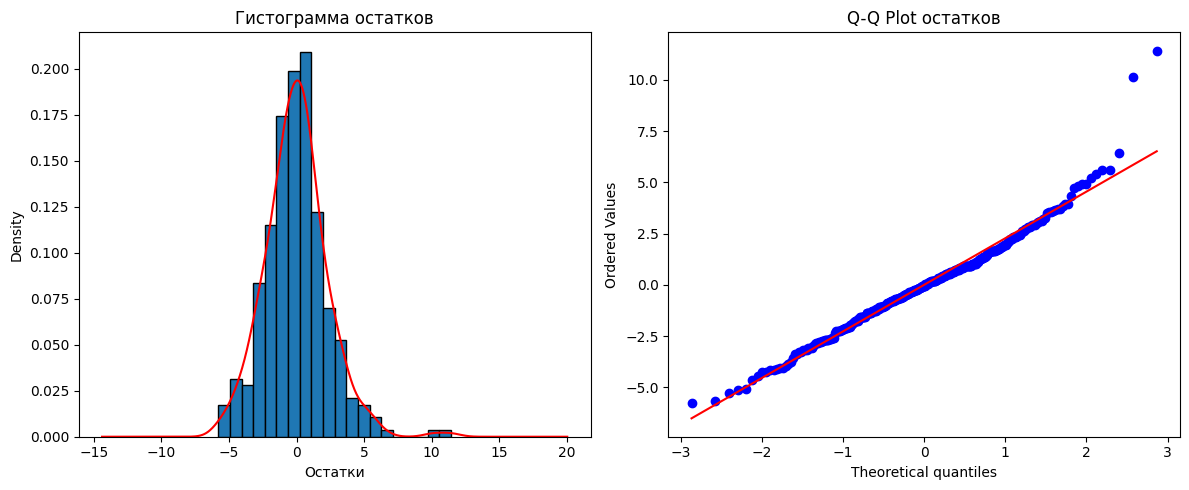

In [ ]:
df["group"] = df["species"] + "-" + df["sex"]

levene_groups = df.groupby("group")["bill_length_mm"].apply(list)
levene_res = stats.levene(*levene_groups)

print(f"statistic = {levene_res.statistic:.2f}, p-value = {levene_res.pvalue:.3g}")
print("Вывод: дисперсии равны" if levene_res.pvalue > 0.05 else "Вывод: дисперсии значимо отличаются")

residuals_bill = model.resid
shapiro_res = stats.shapiro(residuals_bill)

print(f"Тест Шапиро-Уилка: statistic = {shapiro_res.statistic:.3f}, p-value = {shapiro_res.pvalue:.3g}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(residuals_bill, bins=20, edgecolor="black", density=True)
residuals_bill.plot(kind="kde", ax=axes[0], color="red")
axes[0].set_title("Гистограмма остатков")
axes[0].set_xlabel("Остатки")

stats.probplot(residuals_bill, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot остатков")

plt.tight_layout()
plt.show()

При ненормальности остатков следует применять тест Краскела — Уоллиса. Недостатком теста является его однофакторность, и следовательно не может разделять основные эффекты и взаимодействия. Представим два фактора как один с шестью уровнями.

In [ ]:
df["group"] = df["species"] + "-" + df["sex"]
groups = df.groupby("group")["bill_length_mm"].apply(list)

result = stats.kruskal(*groups)
f"statistic = {result.statistic:.2f}, p-value = {result.pvalue:.3g}"

'statistic = 278.67, p-value = 3.85e-58'

Непараметрическим аналогом теста Тьюки является тест Данна.

In [ ]:
sp.posthoc_dunn(df, val_col="bill_length_mm", group_col="group", p_adjust="holm")

,Adelie-Female,Adelie-Male,Chinstrap-Female,Chinstrap-Male,Gentoo-Female,Gentoo-Male
Adelie-Female,1.000000e+00,2.025250e-03,3.816159e-15,1.309546e-34,1.061632e-16,5.805436e-37
Adelie-Male,2.025250e-03,1.000000e+00,7.003896e-07,3.556596e-21,8.975693e-07,1.020873e-20
Chinstrap-Female,3.816159e-15,7.003896e-07,1.000000e+00,1.022012e-03,3.990799e-01,3.102454e-02
Chinstrap-Male,1.309546e-34,3.556596e-21,1.022012e-03,1.000000e+00,3.748988e-06,2.003242e-01
Gentoo-Female,1.061632e-16,8.975693e-07,3.990799e-01,3.748988e-06,1.000000e+00,4.040272e-04
Gentoo-Male,5.805436e-37,1.020873e-20,3.102454e-02,2.003242e-01,4.040272e-04,1.000000e+00


Давайте сделаем вывод немного красочнее.

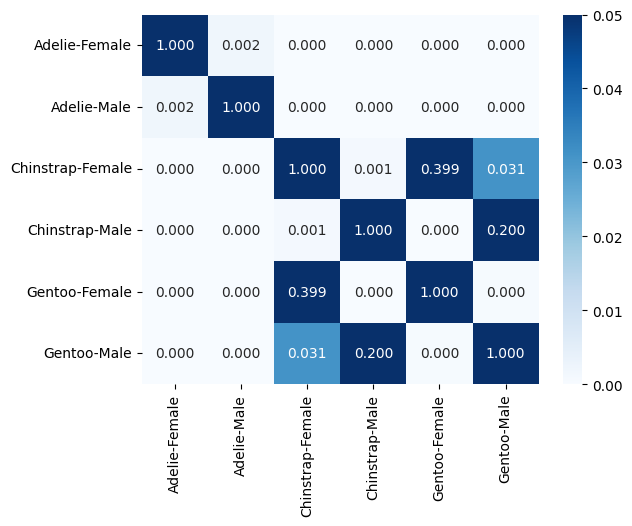

In [ ]:
matrix = sp.posthoc_dunn(df, val_col="bill_length_mm", group_col="group", p_adjust="holm")

sns.heatmap(matrix, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=0.05)
plt.show()

Для непараметрического анализа влияния нескольких факторов и их взаимодействий можно использовать Aligned Rank Transform (ART). У этого метода также есть предпосылки, которые необходимо проверять перед интерпретацией результатов.

In [ ]:
model = art.art("bill_length_mm ~ species * sex", df)
art.anova_art(model)

,Term,Df,Df.res,F,Pr(>F)
0,species,2.0,327.0,484.713345,1.564104e-98
1,sex,1.0,327.0,252.177796,1.706093e-42
2,species:sex,2.0,327.0,3.297661,3.820283e-02


Для парных сравнений метод имеет собственный постхок ART-C.

In [ ]:
art.art_con(model, "species:sex", adjust="tukey")

,contrast,estimate,SE,df,t.ratio,p.value
0,"Adelie,Female - Adelie,Male",-55.410959,6.435323,327.0,-8.610440,0.000000e+00
1,"Adelie,Female - Chinstrap,Female",-162.791096,8.072494,327.0,-20.166146,0.000000e+00
2,"Adelie,Female - Chinstrap,Male",-249.496978,8.072494,327.0,-30.907049,0.000000e+00
3,"Adelie,Female - Gentoo,Female",-145.256613,6.838754,327.0,-21.240217,0.000000e+00
4,"Adelie,Female - Gentoo,Male",-215.623063,6.744392,327.0,-31.970720,0.000000e+00
5,"Adelie,Male - Chinstrap,Female",-107.380137,8.072494,327.0,-13.301977,0.000000e+00
6,"Adelie,Male - Chinstrap,Male",-194.086019,8.072494,327.0,-24.042881,0.000000e+00
7,"Adelie,Male - Gentoo,Female",-89.845654,6.838754,327.0,-13.137723,0.000000e+00
8,"Adelie,Male - Gentoo,Male",-160.212104,6.744392,327.0,-23.754863,0.000000e+00
9,"Chinstrap,Female - Chinstrap,Male",-86.705882,9.429579,327.0,-9.195096,0.000000e+00


### Задание 5

Самостоятельно оцените различия `bill_depth_mm` в группах «вид × пол» с помощью ANOVA. Проверьте предпосылки модели. При соблюдении предпослылок выполните тест Тьюки. При их несоблюдении — тесты Краскела — Уоллиса и Данна. Визуализируйте результат желаемым образом.

                df      sum_sq     mean_sq           F         PR(>F)
species        2.0  870.785183  435.392591  625.495765  1.731587e-112
sex            1.0  188.497172  188.497172  270.799699   9.471310e-45
species:sex    2.0    0.559711    0.279856    0.402048   6.692791e-01
Residual     327.0  227.616853    0.696076         NaN            NaN
Левене p-val: 0.00397
Шапиро p-val: 0.0347
Краскел: KruskalResult(statistic=np.float64(270.7163679832573), pvalue=np.float64(1.9637308505819942e-56))

Тест Данна:
                   Adelie-Female  Adelie-Male  Chinstrap-Female  \
Adelie-Female               1.0       0.0000            1.0000   
Adelie-Male                 0.0       1.0000            0.0006   
Chinstrap-Female            1.0       0.0006            1.0000   
Chinstrap-Male              0.0       1.0000            0.0005   
Gentoo-Female               0.0       0.0000            0.0000   
Gentoo-Male                 0.0       0.0000            0.0002   

                  Chins

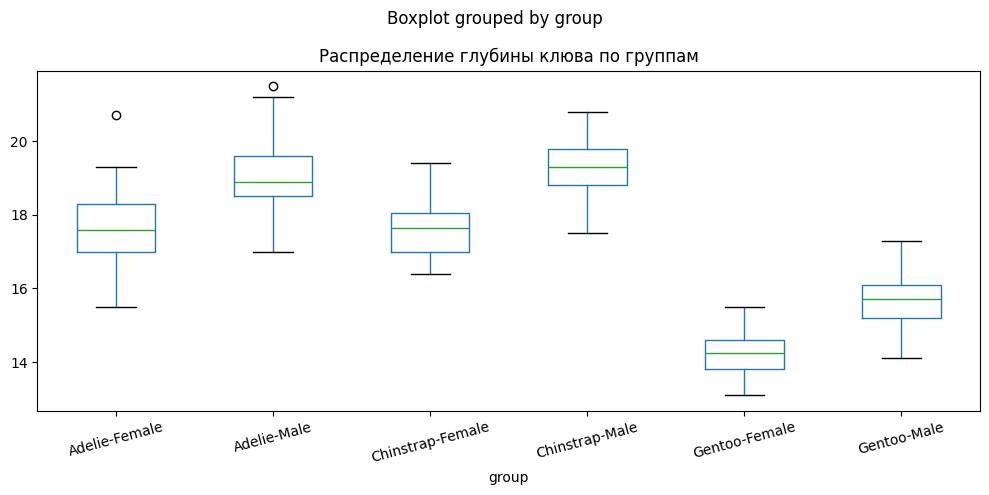

In [ ]:
df["group"] = df["species"] + "-" + df["sex"]

model = ols("bill_depth_mm ~ species * sex", df).fit()
gr = df.groupby("group")["bill_depth_mm"].apply(list)

print(anova_lm(model))
print(f"Левене p-val: {stats.levene(*gr).pvalue:.3g}")
print(f"Шапиро p-val: {stats.shapiro(model.resid).pvalue:.3g}")

print(f"Краскел: {stats.kruskal(*gr)}")
dunn = sp.posthoc_dunn(
    df, val_col="bill_depth_mm", group_col="group", p_adjust="bonferroni"
)
print("\nТест Данна:\n", dunn.round(4))

df.boxplot(column="bill_depth_mm", by="group", figsize=(10, 5), grid=False)
plt.title("Распределение глубины клюва по группам")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()